# 01 – Khám phá dữ liệu CSE-CIC-IDS2018

Thống kê ở mục 1–5 được tính trên **toàn bộ 10 file CSV** (pass streaming trong `dataset_loader.inspect_cicids`). Phân phối đặc trưng ở mục 6–12 dùng **tập làm việc** đã khử trùng lặp (`data/interim/cicids2018_sample.parquet`), vì toàn bộ dữ liệu không vừa RAM.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.utils import visualization as viz
from src.utils.config import project_path
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
FIG, METRICS, EXP = project_path('figures'), project_path('metrics'), project_path('experiments')
%matplotlib inline

## 1. Tổng quan dataset

In [2]:
ins = json.loads((METRICS/'cicids_inspection.json').read_text())
files = pd.DataFrame(ins['files']).T
files['size_MB'] = (files['size_bytes']/2**20).round(1)
files[['rows','header_rows','size_MB','extra_columns']].sort_index()

,rows,header_rows,size_MB,extra_columns
Friday-02-03-2018_TrafficForML_CICFlowMeter.csv,1048575,0,336.0,[]
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv,1048574,1,318.3,[]
Friday-23-02-2018_TrafficForML_CICFlowMeter.csv,1048575,0,365.1,[]
Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv,7948748,0,3867.1,"[Flow ID, Src IP, Src Port, Dst IP]"
Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv,331100,25,102.8,[]
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv,1048575,0,358.5,[]
Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv,1048575,0,364.9,[]
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv,1048575,0,341.6,[]
Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv,1048575,0,313.7,[]
Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv,613071,33,199.6,[]


In [3]:
print('Tổng số dòng:', f"{ins['total_rows']:,}", '| số cột đặc trưng:', ins['n_feature_columns'])
print('Cột hằng số trên toàn bộ dữ liệu:', ins['constant_columns'])

Tổng số dòng: 16,232,943 | số cột đặc trưng: 78
Cột hằng số trên toàn bộ dữ liệu: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']


**Nhận xét.** 10 file, tổng 16,232,943 flow và 78 đặc trưng số. File ngày 20/02 chiếm gần một nửa dữ liệu (7,948,748 dòng, 3.9 GB) và là file duy nhất có thêm 4 cột định danh (`Flow ID`, `Src IP`, `Src Port`, `Dst IP`); các cột này không được dùng vì chỉ có ở một ngày và chỉ định danh máy trong testbed. 59 dòng tiêu đề bị lặp giữa file (3 file) phải được loại khi đọc. 7/10 file có đúng 1,048,575 dòng dữ liệu – bằng giới hạn dòng của Excel trừ tiêu đề – nên dữ liệu các ngày này nhiều khả năng đã bị cắt bớt khi xuất. **Kết luận:** dữ liệu lớn, không đồng nhất giữa các file; cần đọc theo khối, chuẩn hoá schema và không thể coi các file là bản ghi đầy đủ của từng ngày.

## 2. Giá trị thiếu, vô cực, giá trị âm

In [4]:
stats = pd.read_csv(METRICS/'cicids_column_stats_raw.csv')
bad = stats[(stats.nan>0)|(stats.pos_inf>0)|(stats.neg_inf>0)][['feature','nan','pos_inf','neg_inf']]
display(bad)
neg = stats[stats.negative>0][['feature','negative','min']].sort_values('negative', ascending=False)
display(neg)
print('NaN cells:', ins['total_nan_cells'], '| +Inf:', ins['total_pos_inf_cells'], '| -Inf:', ins['total_neg_inf_cells'])

,feature,nan,pos_inf,neg_inf
15,Flow Byts/s,59721,36039,0
16,Flow Pkts/s,0,95760,0


,feature,negative,min
67,Init Bwd Win Byts,8255549,-1.000000e+00
66,Init Fwd Win Byts,4432608,-1.000000e+00
20,Flow IAT Min,15,-9.474050e+11
25,Fwd IAT Min,15,-9.474050e+11
17,Flow IAT Mean,14,-8.282200e+11
2,Flow Duration,14,-9.190110e+11
16,Flow Pkts/s,14,-8.895325e-03
21,Fwd IAT Tot,14,-9.190110e+11
22,Fwd IAT Mean,14,-8.282200e+11
19,Flow IAT Max,3,-8.282200e+11


NaN cells: 59721 | +Inf: 131799 | -Inf: 0


**Nhận xét.** Giá trị thiếu/vô cực chỉ tập trung ở hai cột tốc độ: `Flow Byts/s` (59,721 NaN, 36,039 +Inf) và `Flow Pkts/s` (95,760 +Inf); không có −Inf. Chúng xuất hiện khi thời lượng flow bằng 0 (tốc độ = lượng/0). Giá trị âm có hai loại khác hẳn nhau: (1) `Init Fwd/Bwd Win Byts = −1` ở hàng triệu dòng là giá trị quy ước "không quan sát được TCP window" – mang thông tin, phải giữ; (2) 14–15 dòng có `Flow Duration`/IAT âm tới −9.47·10¹¹ µs – lỗi đồng hồ, không có ý nghĩa vật lý. **Kết luận:** Inf được thay bằng giá trị hữu hạn lớn nhất của train (giữ ý nghĩa "rất nhanh"), NaN tốc độ → 0, thời gian âm → 0, giữ −1.

## 3. Bản ghi trùng lặp

In [5]:
lab = pd.DataFrame({'raw_rows': pd.Series(ins['label_counts']),
                    'unique_rows': pd.Series(ins['unique_rows_per_label'])})
lab['duplicate_share'] = 1 - lab.unique_rows/lab.raw_rows
print('Dòng trùng (đặc trưng + nhãn):', f"{ins['duplicate_rows_features_and_label']:,}",
      f"({ins['duplicate_rows_features_and_label']/ins['total_rows']:.1%})")
print('Vector đặc trưng mang >1 nhãn:', f"{ins['conflicting_label_feature_vectors']:,}",
      '| số dòng liên quan:', f"{ins['rows_in_conflicting_vectors']:,}")
lab.sort_values('raw_rows', ascending=False).style.format({'raw_rows':'{:,}','unique_rows':'{:,}','duplicate_share':'{:.1%}'})

Dòng trùng (đặc trưng + nhãn): 4,243,106 (26.1%)
Vector đặc trưng mang >1 nhãn: 22,359 | số dòng liên quan: 423,290


,raw_rows,unique_rows,duplicate_share
Benign,"13,484,708","10,637,200",21.1%
DDoS-HOIC,"686,012","198,861",71.0%
DDoS-LOIC-HTTP,"576,191","575,364",0.1%
DoS-Hulk,"461,912","145,199",68.6%
Bot,"286,191","144,535",49.5%
BruteForce-FTP,"193,360",54,100.0%
BruteForce-SSH,"187,589","94,048",49.9%
Infiltration,"161,934","140,610",13.2%
DoS-SlowHTTPTest,"139,890",55,100.0%
DoS-GoldenEye,"41,508","41,406",0.2%


**Nhận xét.** 4,243,106 dòng (26.1%) là bản sao hoàn toàn (cùng đặc trưng và nhãn). Mức trùng rất khác nhau giữa các lớp: FTP-BruteForce có 193,360 dòng nhưng chỉ 54 vector khác nhau, DoS-SlowHTTPTest 139,890 dòng nhưng chỉ 55 vector – hai lớp này gần như chỉ là một vài flow lặp lại (tấn công không trao đổi dữ liệu thực). DDoS-HOIC trùng 71%, DoS-Hulk 68.6%, trong khi LOIC-HTTP, GoldenEye, LOIC-UDP gần như không trùng. Ngoài ra 22,359 vector mang nhiều hơn một nhãn (423,290 dòng). **Kết luận:** nếu không khử trùng lặp, các lớp lặp lại sẽ thống trị dữ liệu và cùng một flow rơi vào cả train và test, làm kết quả lạc quan giả tạo. Dự án khử trùng lặp trước khi chia và loại các vector xung đột nhãn.

## 4. Phân phối lớp

In [6]:
from src.data_processing.dataset_loader import FAMILY_OF
raw = pd.Series(ins['label_counts'])
viz.bar_counts(raw, 'CICIDS2018: số flow theo nhãn gốc (toàn bộ dữ liệu)', FIG/'eda_class_distribution_fine.png')
fam = raw.groupby(raw.index.map(FAMILY_OF)).sum()
viz.bar_counts(fam, 'CICIDS2018: số flow theo nhóm tấn công', FIG/'eda_class_distribution_family.png')
display(fam.sort_values(ascending=False).to_frame('rows').assign(share=lambda d: d.rows/d.rows.sum()))
by_day = pd.DataFrame(ins['label_counts_by_day']).fillna(0).astype(int)
by_day

,rows,share
BENIGN,13484708,0.830700
DDoS,1263933,0.077862
DoS,654300,0.040307
BruteForce,380949,0.023468
Botnet,286191,0.017630
Infiltration,161934,0.009976
WebAttack,928,0.000057


,2018-02-14,2018-02-15,2018-02-16,2018-02-20,2018-02-21,2018-02-22,2018-02-23,2018-02-28,2018-03-01,2018-03-02
Benign,667626,996077,446772,7372557,360833,1048213,1048009,544200,238037,762384
BruteForce-FTP,193360,0,0,0,0,0,0,0,0,0
BruteForce-SSH,187589,0,0,0,0,0,0,0,0,0
DoS-GoldenEye,0,41508,0,0,0,0,0,0,0,0
DoS-Slowloris,0,10990,0,0,0,0,0,0,0,0
DoS-SlowHTTPTest,0,0,139890,0,0,0,0,0,0,0
DoS-Hulk,0,0,461912,0,0,0,0,0,0,0
DDoS-LOIC-HTTP,0,0,0,576191,0,0,0,0,0,0
DDoS-LOIC-UDP,0,0,0,0,1730,0,0,0,0,0
DDoS-HOIC,0,0,0,0,686012,0,0,0,0,0


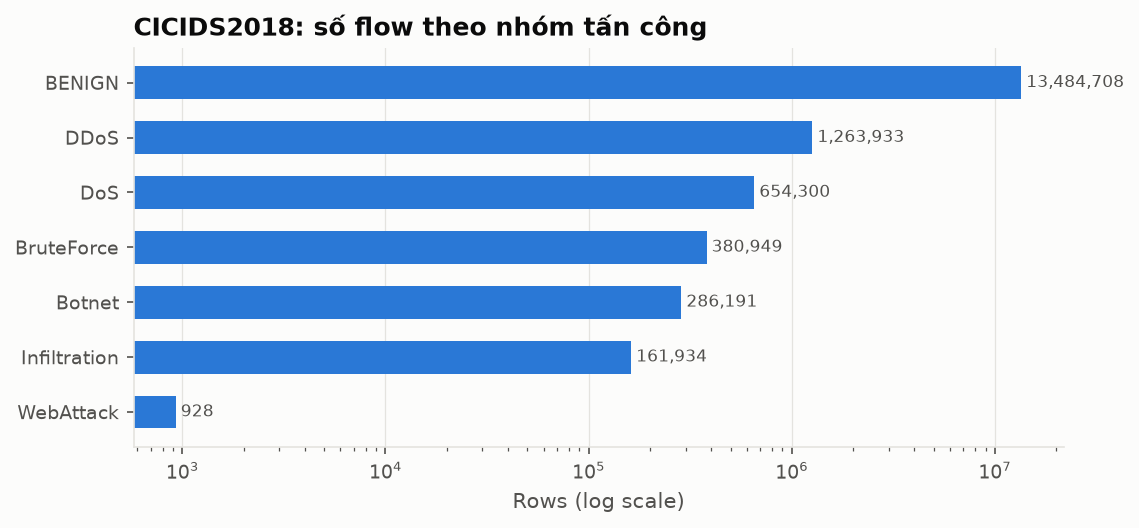

In [7]:
from IPython.display import Image
Image(FIG/'eda_class_distribution_family.png')

**Nhận xét.** Benign chiếm 83.07% (13.48 triệu flow). Trong các nhóm tấn công, DDoS (1.26 triệu) và DoS (654k) lớn nhất; WebAttack chỉ có 928 flow (611 brute force web, 230 XSS, 87 SQLi) – tỉ lệ Benign : WebAttack ≈ 14,531 : 1. Bảng theo ngày cho thấy mỗi loại tấn công chỉ xuất hiện trong 1–2 ngày (ví dụ Bot chỉ ngày 02/03, Infiltration chỉ 28/02 và 01/03). CICIDS2018 không có lớp PortScan. **Kết luận:** (1) phải dùng chỉ số không bị lớp đa số chi phối (macro-F1, recall từng lớp, FPR) thay vì accuracy; (2) không thể chia train/test theo ngày cho bài toán đa lớp vì lớp ở ngày test sẽ không có trong train – dùng chia phân tầng và chia theo thời gian trong từng nhãn.

## 5. Thống kê mô tả (toàn bộ dữ liệu, giá trị hữu hạn)

In [8]:
stats.set_index('feature')[['min','max','mean','std','median_2pct_sample','zero']].style.format('{:.4g}')

,min,max,mean,std,median_2pct_sample,zero
feature,,,,,,
Dst Port,0,6.554e+04,9164,1.892e+04,80,2.383e+05
Protocol,0,17,8.754,4.92,6,2.383e+05
Flow Duration,-9.19e+11,1.2e+08,1.181e+07,4.94e+08,2.097e+04,9.576e+04
Tot Fwd Pkts,1,3.096e+05,23.53,1521,2,0
Tot Bwd Pkts,0,1.231e+05,6.313,164,1,4.137e+06
TotLen Fwd Pkts,0,1.444e+08,973,6.217e+04,43,5.032e+06
TotLen Bwd Pkts,0,1.564e+08,4731,2.345e+05,101,6.007e+06
Fwd Pkt Len Max,0,6.444e+04,200.8,303.5,40,5.032e+06
Fwd Pkt Len Min,0,1460,11.08,24.23,0,1.2e+07


**Nhận xét.** Hầu hết đặc trưng trải rất rộng: thời gian tới ~1.2·10⁸ µs, `Flow Byts/s` tới ~10⁹, trong khi trung vị nhỏ hơn hàng bậc độ lớn – phân phối lệch phải mạnh. Nhiều cột có tỉ lệ giá trị 0 rất cao (cờ TCP, độ dài gói chiều về). 8 cột hằng số trên toàn bộ dữ liệu (`Bwd PSH Flags`, `Bwd URG Flags`, 6 cột bulk) không mang thông tin. **Kết luận:** loại cột hằng; với mô hình nhạy thang đo (MLP, Logistic Regression, Gaussian) dùng biến đổi sign·log1p trước khi chuẩn hoá; mô hình cây không cần scale.

## 6. Phân phối đặc trưng (tập làm việc)

In [9]:
sample = pd.read_parquet(project_path('interim')/'cicids2018_sample.parquet')
print(sample.shape)
sample['Family'].value_counts()

(1779198, 85)


Family
BENIGN          900475
DDoS            302041
DoS             196568
Botnet          144535
Infiltration    140610
BruteForce       94102
WebAttack          867
Name: count, dtype: int64

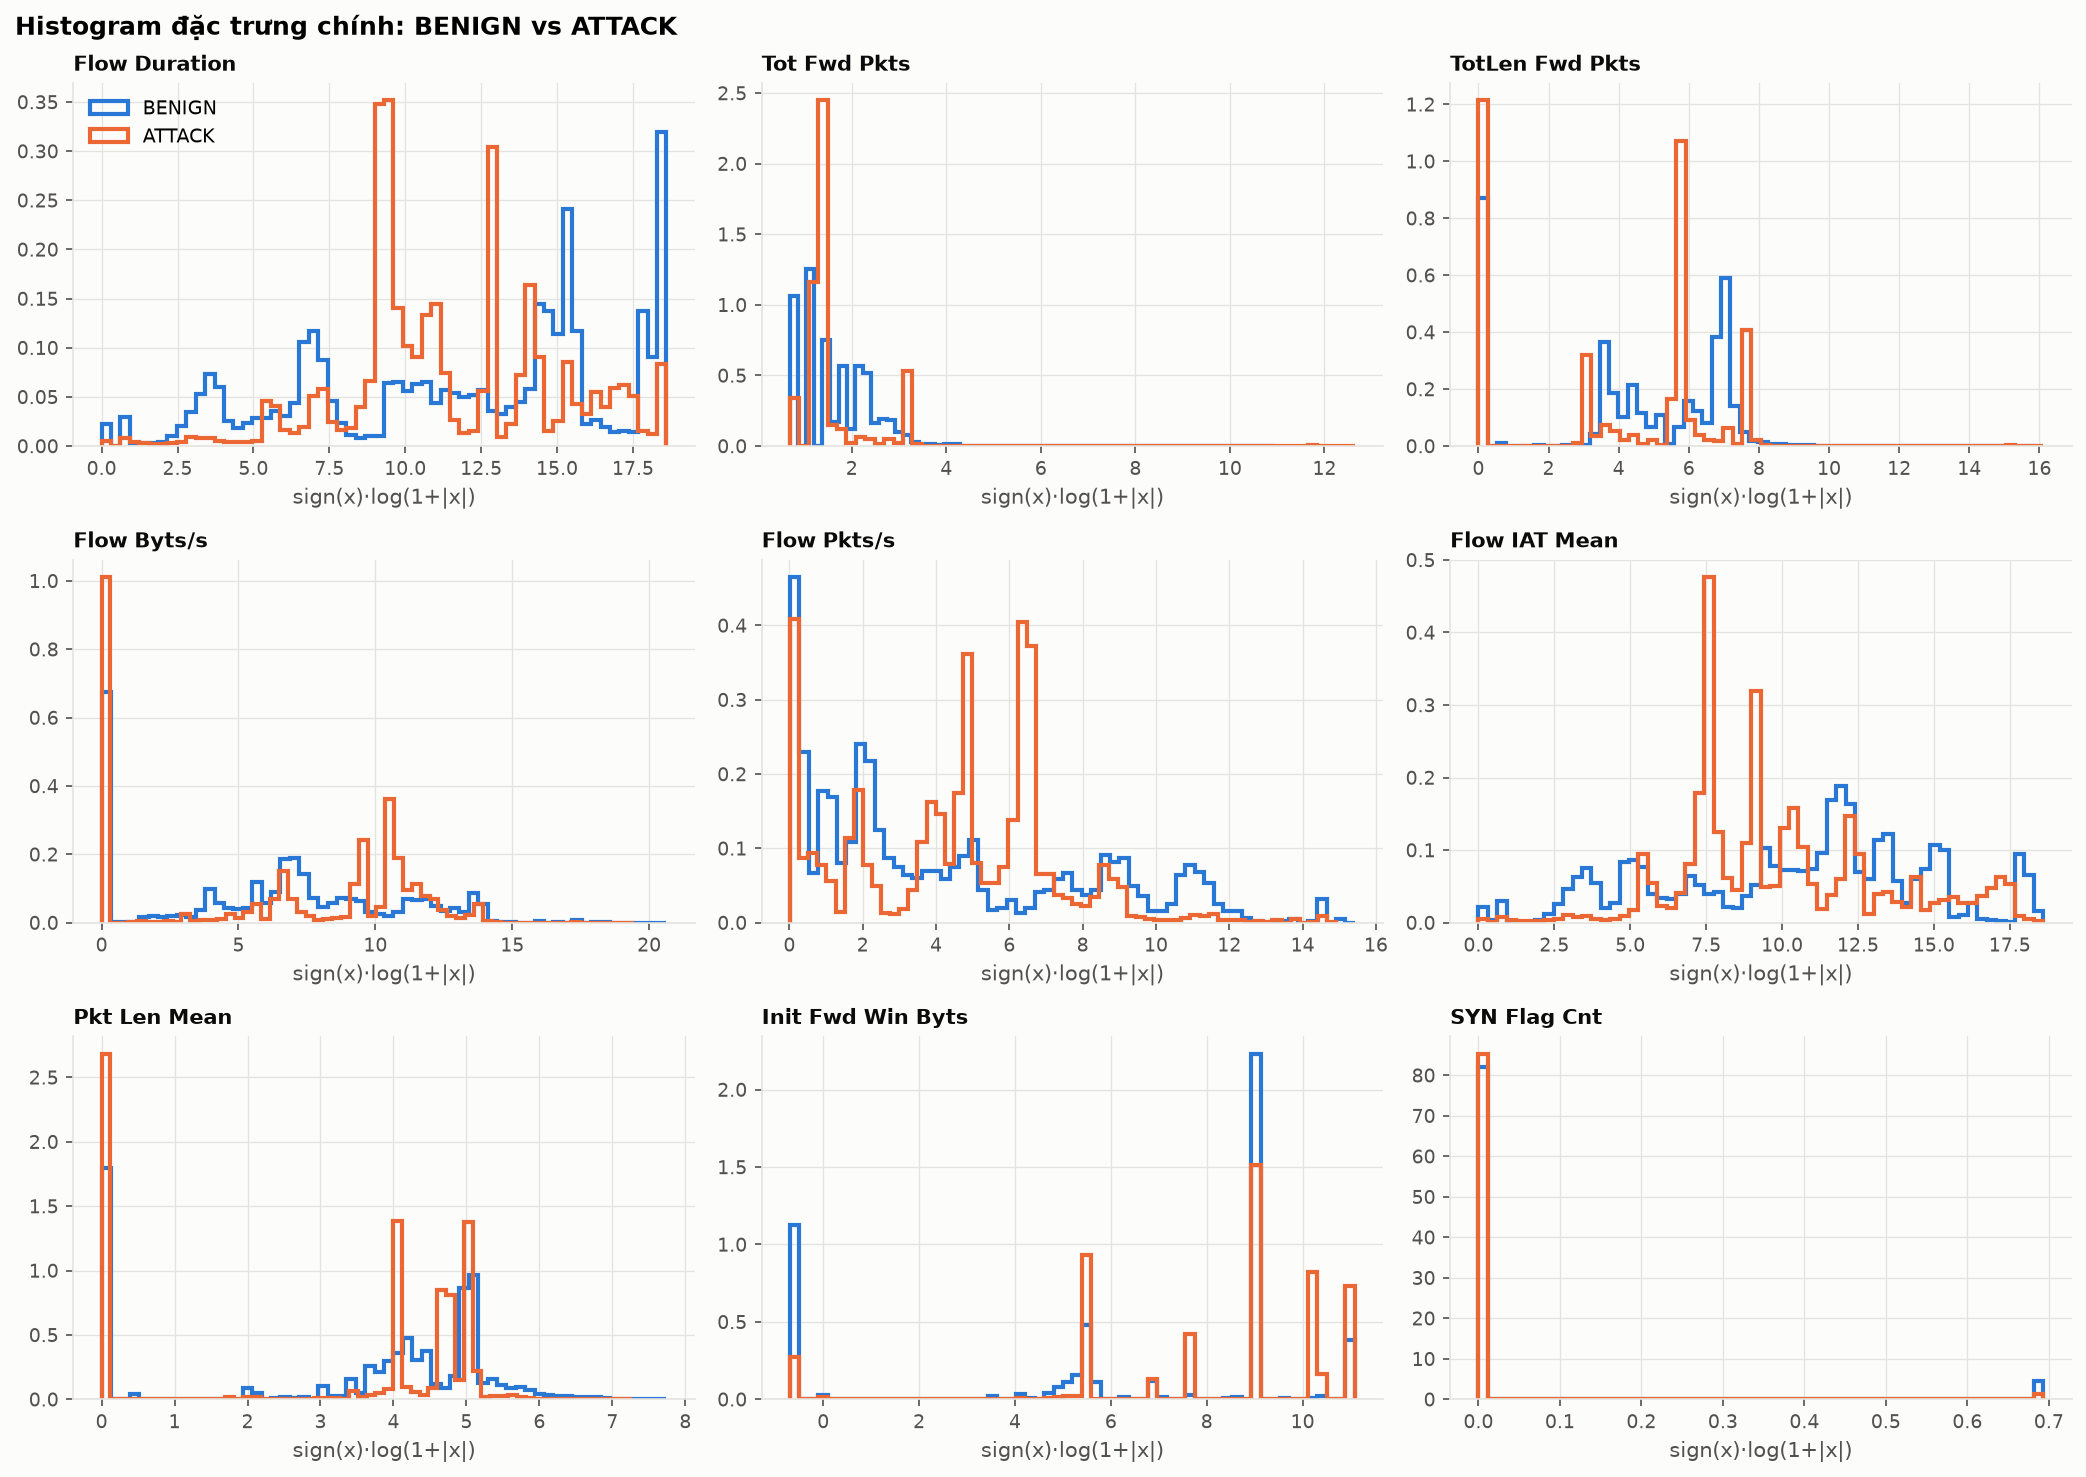

In [10]:
key = ['Flow Duration','Tot Fwd Pkts','TotLen Fwd Pkts','Flow Byts/s','Flow Pkts/s','Flow IAT Mean',
       'Pkt Len Mean','Init Fwd Win Byts','SYN Flag Cnt']
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, f in zip(axes.ravel(), key):
    for i, (name, mask) in enumerate([('BENIGN', sample.IsAttack==0), ('ATTACK', sample.IsAttack==1)]):
        v = sample.loc[mask, f].replace([np.inf,-np.inf], np.nan).dropna()
        ax.hist(np.sign(v)*np.log1p(np.abs(v)), bins=60, density=True, histtype='step', linewidth=2,
                color=viz.CATEGORICAL[i], label=name)
    ax.set_title(f, loc='left', fontsize=10); ax.set_xlabel('sign(x)·log(1+|x|)')
axes[0,0].legend()
fig.suptitle('Histogram đặc trưng chính: BENIGN vs ATTACK', x=0.01, ha='left', fontweight="bold")
fig.tight_layout(); viz.save(fig, FIG/'eda_histograms.png')
Image(FIG/'eda_histograms.png')

**Nhận xét.** Trên thang log, phân phối BENIGN trải rộng và nhiều đỉnh (nhiều loại ứng dụng), còn ATTACK tập trung thành các đỉnh nhọn: ví dụ `Flow Duration` của tấn công có đỉnh quanh e^9.5 và e^12.9 µs, `Flow Pkts/s` có đỉnh quanh e^5 và e^6.3, `Pkt Len Mean` có đỉnh ở 0 (flow không payload) và ~e^4. Đây là dấu hiệu của traffic do công cụ tự động sinh ra, lặp lại gần như y hệt. `Init Fwd Win Byts` của tấn công rơi vào vài giá trị riêng biệt (vd. ~e^10.2, ~e^11) khác với BENIGN – có thể phản ánh hệ điều hành của máy tấn công trong testbed hơn là bản chất tấn công. `SYN Flag Cnt` gần như luôn bằng 0 ở cả hai lớp (xem phần tương quan). **Kết luận:** nhiều đặc trưng tách được hai lớp, nhưng một phần khả năng tách đến từ đặc điểm của môi trường mô phỏng; cần thí nghiệm ablation để đo mức phụ thuộc vào các đặc trưng kiểu này.

## 7. Boxplot theo nhóm tấn công

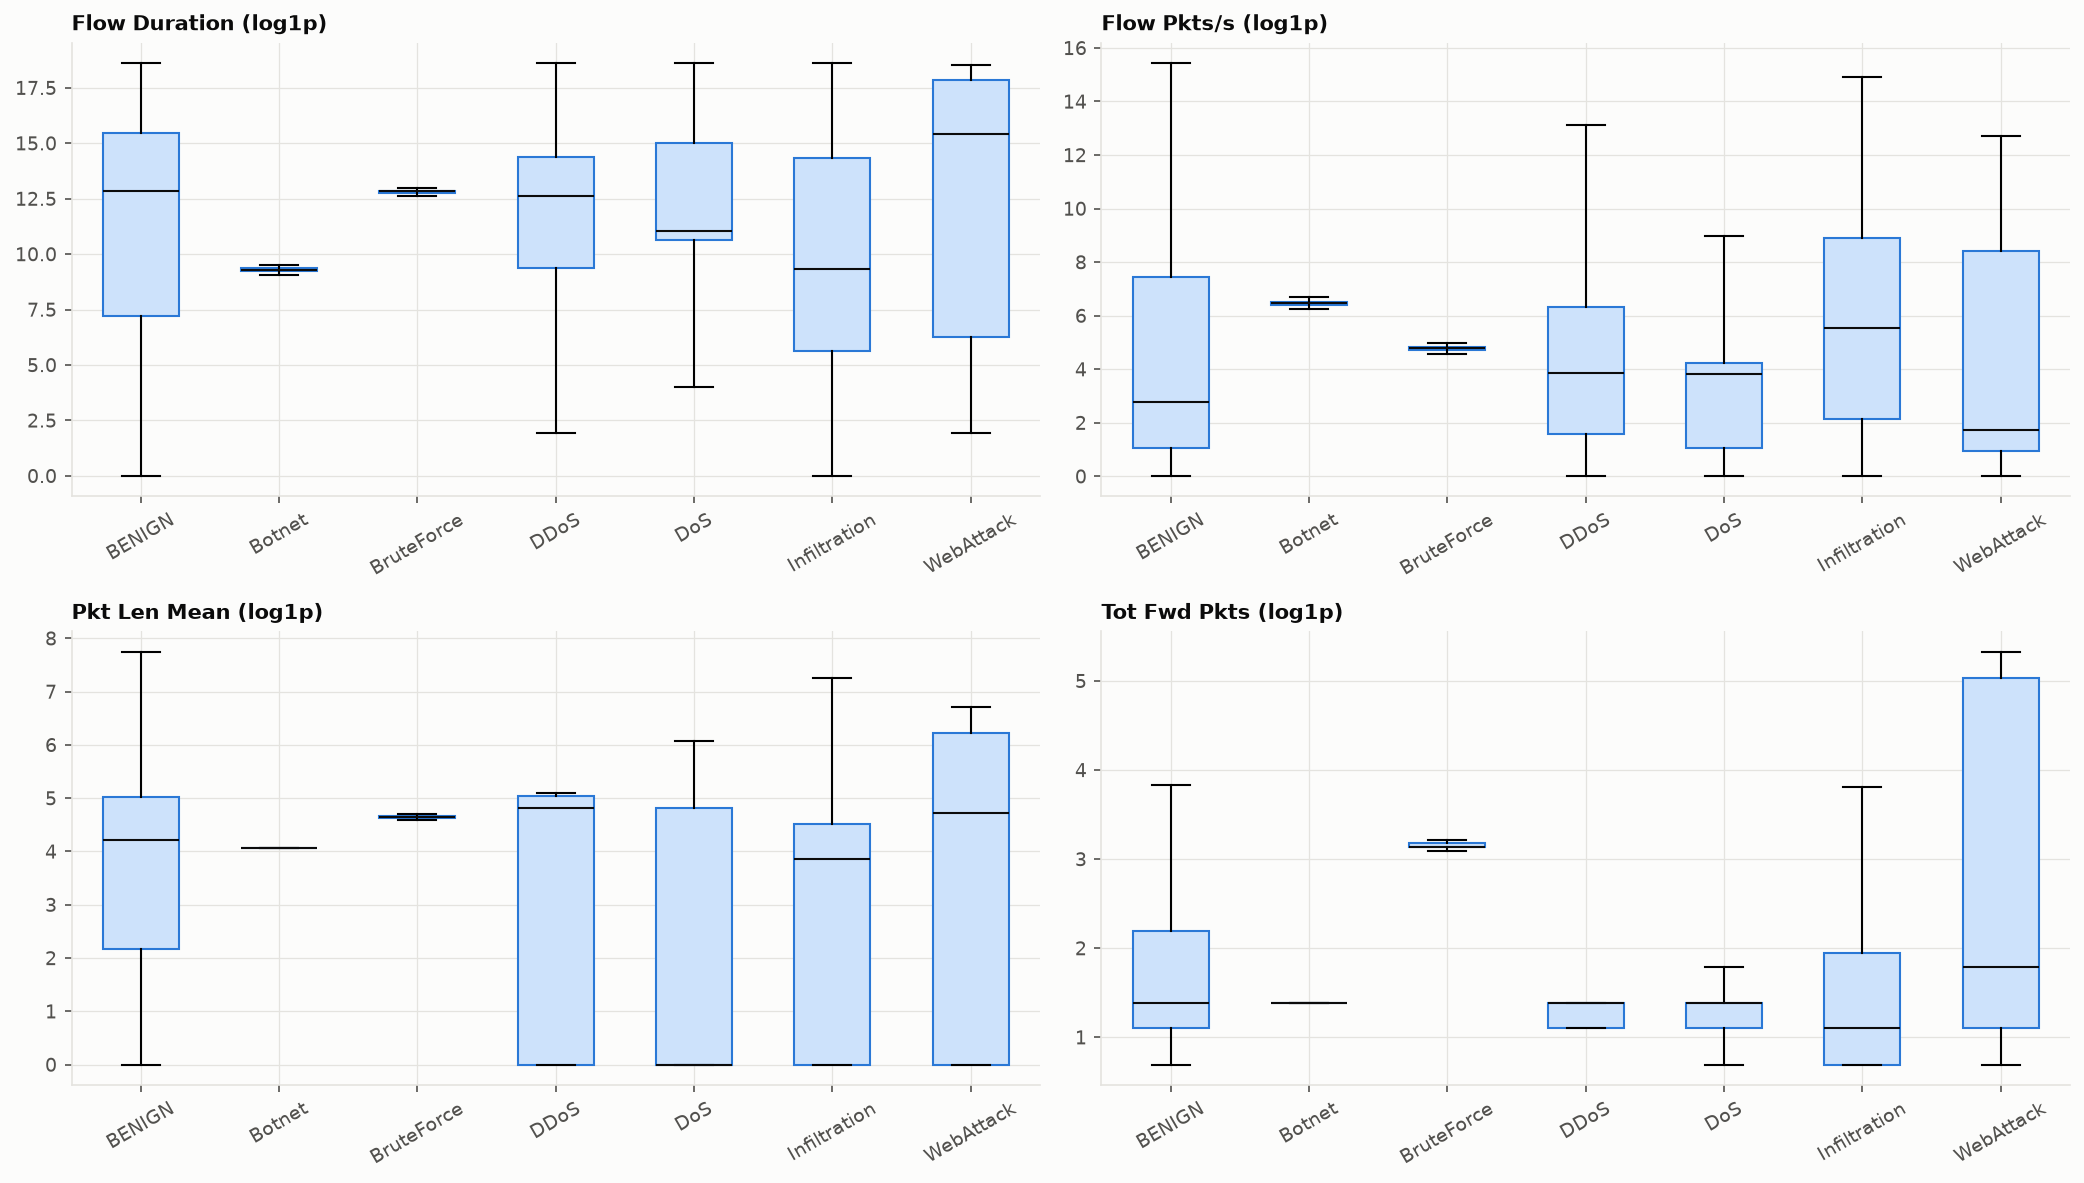

In [11]:
fams = ['BENIGN'] + sorted(f for f in sample.Family.unique() if f!='BENIGN')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, f in zip(axes.ravel(), ['Flow Duration','Flow Pkts/s','Pkt Len Mean','Tot Fwd Pkts']):
    data = [np.log1p(np.clip(sample.loc[sample.Family==fm, f].replace([np.inf,-np.inf], np.nan).dropna(), 0, None)) for fm in fams]
    bp = ax.boxplot(data, tick_labels=fams, showfliers=False, patch_artist=True, widths=0.55)
    for patch in bp['boxes']: patch.set_facecolor('#cde2fb'); patch.set_edgecolor(viz.CATEGORICAL[0])
    for med in bp['medians']: med.set_color(viz.TEXT)
    ax.set_title(f + ' (log1p)', loc='left', fontsize=10); ax.tick_params(axis='x', rotation=30)
fig.tight_layout(); viz.save(fig, FIG/'eda_boxplots.png')
Image(FIG/'eda_boxplots.png')

**Nhận xét.** Botnet và BruteForce có hộp gần như là một đường thẳng ở cả 4 đặc trưng: các flow có thời lượng, tốc độ và kích thước gần như giống hệt nhau (Bot liên lạc C&C định kỳ; Patator/SSH brute force lặp cùng một trao đổi). DoS/DDoS có `Tot Fwd Pkts` rất thấp (trung vị 3 gói) và `Pkt Len Mean` bằng 0 ở phần lớn flow DoS – nhiều kết nối ngắn không payload. Ngược lại Infiltration có phân phối rộng tương tự BENIGN ở mọi đặc trưng. Trung vị theo nhóm (bảng mục 9) xác nhận: Infiltration có `Flow Duration` trung vị 11,090 µs, `Tot Fwd Pkts` 2, `Init Fwd Win Byts` 980 – không có đặc điểm riêng rõ rệt. **Kết luận:** dự đoán Botnet, BruteForce, DoS, DDoS sẽ dễ; Infiltration là lớp khó nhất vì hành vi của máy bị nhiễm phần lớn là traffic bình thường.

## 8. Ma trận tương quan

Số cặp |r| > 0.98: 38


,,|r|
TotLen Fwd Pkts,Subflow Fwd Byts,1.000000
RST Flag Cnt,ECE Flag Cnt,1.000000
Tot Bwd Pkts,Subflow Bwd Pkts,1.000000
Fwd Pkt Len Mean,Fwd Seg Size Avg,1.000000
Fwd PSH Flags,SYN Flag Cnt,1.000000
Tot Fwd Pkts,Subflow Fwd Pkts,1.000000
Fwd URG Flags,CWE Flag Count,1.000000
Bwd Pkt Len Mean,Bwd Seg Size Avg,1.000000
TotLen Bwd Pkts,Subflow Bwd Byts,1.000000
Subflow Fwd Pkts,Fwd Act Data Pkts,0.999922


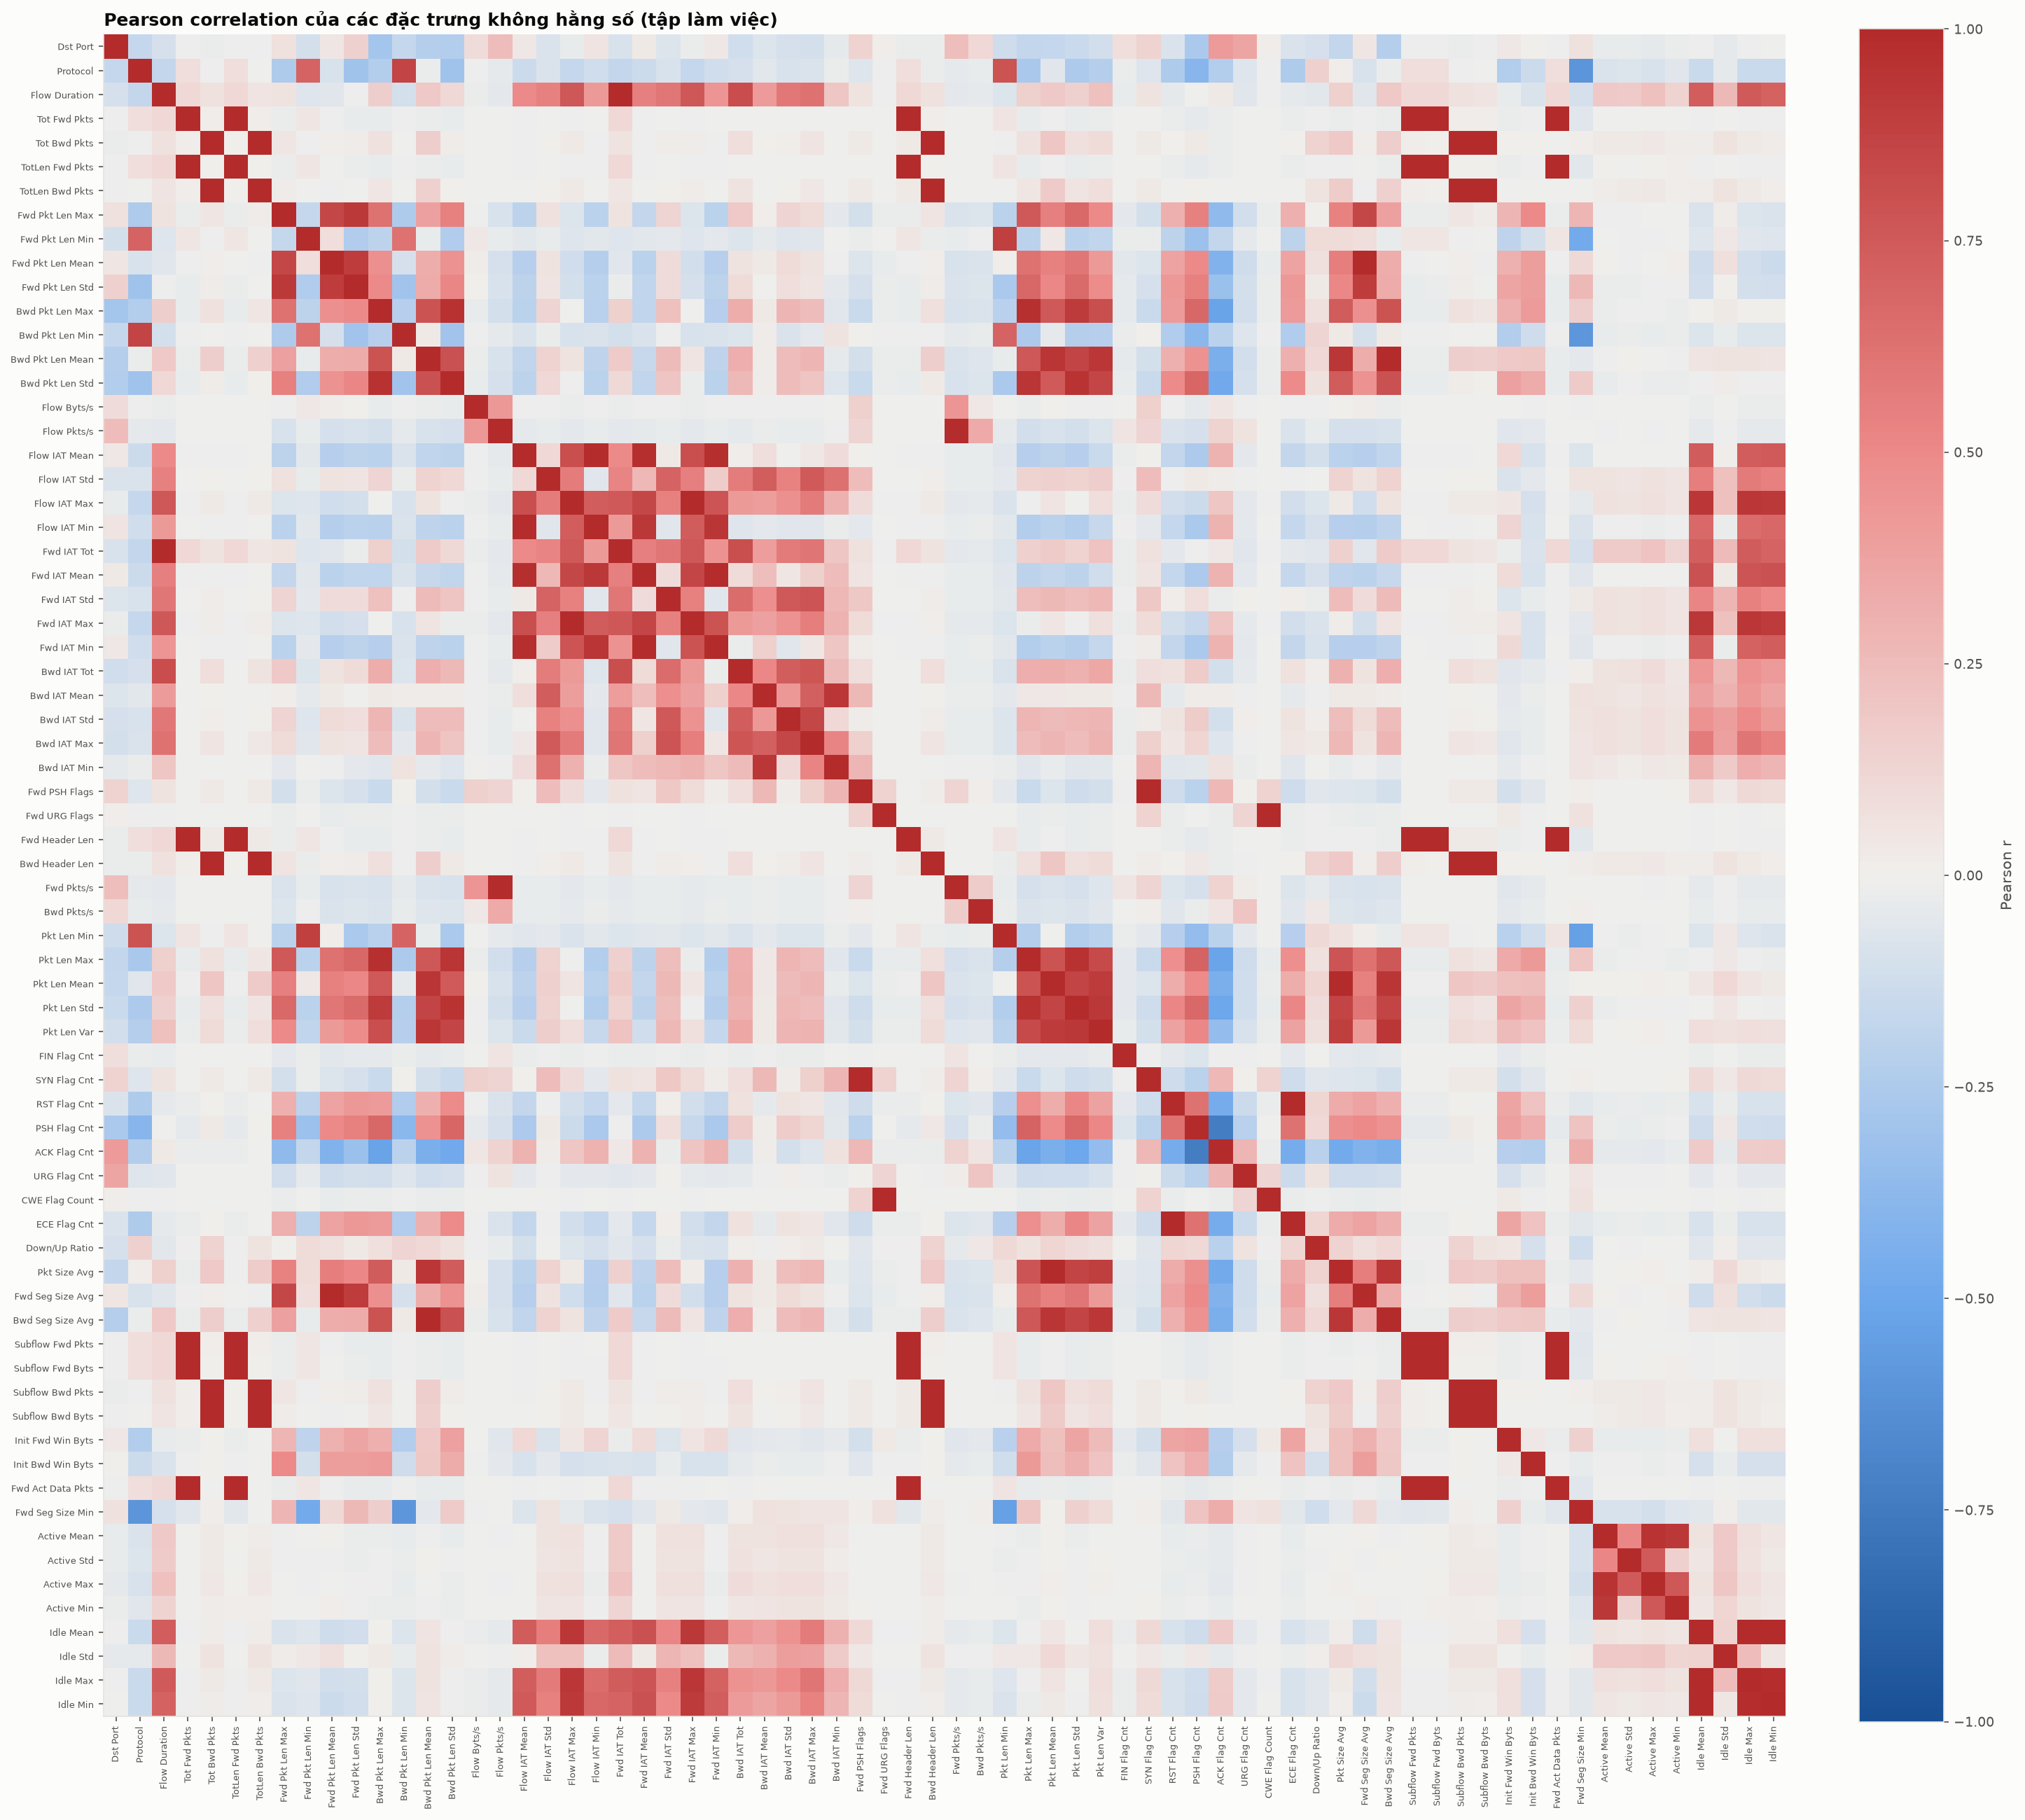

In [12]:
from src.data_processing.feature_extractor import CIC_FEATURE_COLUMNS
num = sample[CIC_FEATURE_COLUMNS].replace([np.inf,-np.inf], np.nan)
num = num.loc[:, num.nunique() > 1]
corr = num.sample(min(len(num), 200_000), random_state=0).corr()
viz.correlation_heatmap(corr, 'Pearson correlation của các đặc trưng không hằng số (tập làm việc)', FIG/'eda_correlation_heatmap.png')
pairs = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print('Số cặp |r| > 0.98:', int((pairs > 0.98).sum()))
display(pairs.head(15).to_frame('|r|'))
Image(FIG/'eda_correlation_heatmap.png')

**Nhận xét.** Có 38 cặp đặc trưng với |r| > 0.98. Nhiều cặp là trùng lặp theo định nghĩa: `Subflow * ` ≡ tổng tương ứng (r = 1), `Fwd/Bwd Seg Size Avg` ≡ `Fwd/Bwd Pkt Len Mean`, `Tot Fwd Pkts` ≈ `Fwd Header Len` (header TCP gần như cố định nên tổng header tỉ lệ với số gói). Hai cặp bất thường: `SYN Flag Cnt` ≡ `Fwd PSH Flags` và `CWE Flag Count` ≡ `Fwd URG Flags` (r = 1) – dấu hiệu lỗi ánh xạ cột trong bản CSV CICFlowMeter, vì về ngữ nghĩa các cờ này độc lập. **Kết luận:** loại đặc trưng dư thừa bằng bộ lọc tương quan (giữ đặc trưng có hạng quan trọng cao hơn) – bước chọn đặc trưng loại 20 cột; không nên diễn giải `SYN Flag Cnt` của dataset như số gói SYN thật.

## 9. So sánh Normal vs Attack và 10. Phân tích theo loại tấn công

In [13]:
cols = ['Flow Duration','Tot Fwd Pkts','Tot Bwd Pkts','TotLen Fwd Pkts','TotLen Bwd Pkts','Flow Pkts/s',
        'Pkt Len Mean','SYN Flag Cnt','ACK Flag Cnt','FIN Flag Cnt','RST Flag Cnt','Init Fwd Win Byts']
sample.groupby('Family')[cols].median().T.style.format('{:.4g}')

Family,BENIGN,Botnet,BruteForce,DDoS,DoS,Infiltration,WebAttack
Flow Duration,3.863e+05,1.091e+04,3.746e+05,3.082e+05,6.218e+04,1.109e+04,5.01e+06
Tot Fwd Pkts,3,3,22,3,3,2,5
Tot Bwd Pkts,2,4,22,4,0,1,1
TotLen Fwd Pkts,97,326,1928,20,0,40,646
TotLen Bwd Pkts,231,129,2665,935,0,72,0
Flow Pkts/s,15.88,642.2,117.8,45.73,44.14,337.3,4.562
Pkt Len Mean,67.2,56.88,102.4,123,0,46.4,112.2
SYN Flag Cnt,0,0,0,0,0,0,0
ACK Flag Cnt,0,0,0,0,1,0,0
FIN Flag Cnt,0,0,0,0,0,0,0


In [14]:
top_ports = (sample.groupby('FineLabel')['Dst Port'].agg(lambda s: ', '.join(f"{int(p)}({c/len(s):.0%})" for p, c in s.value_counts().head(3).items())))
proto = sample.groupby('FineLabel')['Protocol'].agg(lambda s: dict(s.value_counts(normalize=True).round(3)))
pd.DataFrame({'top_dst_ports': top_ports, 'protocol_share': proto, 'rows': sample.FineLabel.value_counts()})

,top_dst_ports,protocol_share,rows
FineLabel,,,
Benign,"53(19%), 3389(17%), 443(16%)","{6.0: 0.779, 17.0: 0.2, 0.0: 0.021}",900475
Bot,"8080(97%), 0(0%), 50891(0%)","{6.0: 0.998, 0.0: 0.002}",144535
BruteForce-FTP,21(100%),{6.0: 1.0},54
BruteForce-SSH,"22(100%), 21(0%)",{6.0: 1.0},94048
DDoS-HOIC,80(100%),{6.0: 1.0},150147
DDoS-LOIC-HTTP,80(100%),"{6.0: 0.999, 17.0: 0.001}",150164
DDoS-LOIC-UDP,80(100%),{17.0: 1.0},1730
DoS-GoldenEye,80(100%),{6.0: 1.0},41406
DoS-Hulk,80(100%),{6.0: 1.0},145199


**Nhận xét.** Mỗi loại tấn công gần như gắn với một cổng đích cố định: Bot → 8080 (97%), SSH brute force → 22 (100%), FTP brute force và SlowHTTPTest → 21 (100%), mọi DoS/DDoS → 80 (100%), SQLi → 80; trong khi BENIGN và Infiltration phân tán (53, 3389, 443...). LOIC-UDP là tấn công duy nhất dùng UDP 100%. **Kết luận:** `Dst Port` là đặc trưng rất mạnh nhưng có nguy cơ là "đường tắt" của testbed (mô hình học "cổng 21 = tấn công FTP" thay vì hành vi). Dự án giữ `Dst Port` (dịch vụ đích là thông tin hợp lệ của IDS) nhưng đo bằng ablation mức giảm hiệu năng khi bỏ nó.

## 11. Mất cân bằng lớp

In [15]:
fc = sample.Family.value_counts()
print('Tỉ lệ lớn nhất / nhỏ nhất (tập làm việc):', round(fc.max()/fc.min(), 1))
print('Tỉ lệ lớn nhất / nhỏ nhất (toàn bộ dữ liệu):', round(fam.max()/fam.min(), 1))
split = pd.read_csv(METRICS/'split_distribution_family.csv', index_col=0)
split.assign(train_share=lambda d: d.train/d.total, val_share=lambda d: d.val/d.total, test_share=lambda d: d.test/d.total)

Tỉ lệ lớn nhất / nhỏ nhất (tập làm việc): 1038.6
Tỉ lệ lớn nhất / nhỏ nhất (toàn bộ dữ liệu): 14530.9


,train,val,test,total,train_share,val_share,test_share
Family,,,,,,,
BENIGN,629006,134788,134787,898581,0.699999,0.150001,0.150000
DDoS,211429,45305,45307,302041,0.700001,0.149996,0.150003
DoS,137589,29483,29484,196556,0.699999,0.149998,0.150003
Botnet,101174,21681,21680,144535,0.699997,0.150005,0.149998
Infiltration,97101,20808,20807,138716,0.699999,0.150004,0.149997
BruteForce,65857,14112,14112,94081,0.700003,0.149998,0.149998
WebAttack,599,128,128,855,0.700585,0.149708,0.149708


**Nhận xét.** Toàn bộ dữ liệu: lớp lớn nhất/nhỏ nhất ≈ 14,531 : 1; tập làm việc sau lấy mẫu ≈ 1,039 : 1 (BENIGN 898,581 vs WebAttack 855). Chia phân tầng giữ đúng tỉ lệ 70/15/15 cho mọi lớp (kể cả WebAttack: 599/128/128). **Kết luận:** lấy mẫu đã giảm mất cân bằng nhưng WebAttack vẫn cực hiếm; đánh giá phải dùng macro-F1 và recall từng lớp. So sánh class weight / undersampling / SMOTE được thực hiện riêng (DATA_PREPROCESSING.md §9).

## 12. Phân tích ngoại lai (IQR)

In [16]:
feat = ['Flow Duration','Tot Fwd Pkts','TotLen Fwd Pkts','Flow Byts/s','Flow Pkts/s','Pkt Len Max','Flow IAT Max']
rows = []
ben = sample[sample.IsAttack==0]
for f in feat:
    v = ben[f].replace([np.inf,-np.inf], np.nan).dropna()
    q1, q3 = v.quantile([.25,.75]); hi = q3 + 3*(q3-q1)
    out = sample[f].replace([np.inf,-np.inf], np.nan) > hi
    rows.append({'feature': f, 'upper_fence(benign, 3*IQR)': hi, 'outlier_share_benign': out[sample.IsAttack==0].mean(),
                 'outlier_share_attack': out[sample.IsAttack==1].mean(),
                 'attack_share_among_outliers': sample.loc[out, 'IsAttack'].mean()})
pd.DataFrame(rows).style.format({'upper_fence(benign, 3*IQR)':'{:.4g}','outlier_share_benign':'{:.1%}',
                                  'outlier_share_attack':'{:.1%}','attack_share_among_outliers':'{:.1%}'})

,feature,"upper_fence(benign, 3*IQR)",outlier_share_benign,outlier_share_attack,attack_share_among_outliers
0,Flow Duration,2.082e+07,18.2%,8.3%,30.7%
1,Tot Fwd Pkts,26,1.7%,0.5%,23.5%
2,TotLen Fwd Pkts,3650,0.7%,0.4%,33.5%
3,Flow Byts/s,3.697e+04,19.4%,32.7%,62.1%
4,Flow Pkts/s,6814,16.9%,4.6%,20.8%
5,Pkt Len Max,4599,0.0%,0.0%,0.0%
6,Flow IAT Max,1.761e+07,11.5%,7.5%,38.9%


**Nhận xét.** Dùng hàng rào Q3 + 3·IQR của BENIGN: 17–19% flow BENIGN đã vượt ngưỡng ở `Flow Duration`, `Flow Byts/s`, `Flow Pkts/s` – "ngoại lai" là một phần bình thường của traffic thật (flow dài, bùng nổ). Ở `Flow Byts/s`, 32.7% flow tấn công vượt ngưỡng và 62.1% các điểm vượt ngưỡng là tấn công (so với ~49% tấn công trong tập làm việc). **Kết luận:** loại ngoại lai sẽ xoá khoảng 1/5 traffic bình thường và một phần lớn tín hiệu tấn công; dự án giữ toàn bộ, dùng mô hình cây (bất biến với giá trị cực đoan) và biến đổi log cho mô hình nhạy thang đo.

## 13. Pairplot (mẫu nhỏ) và 14. Feature importance

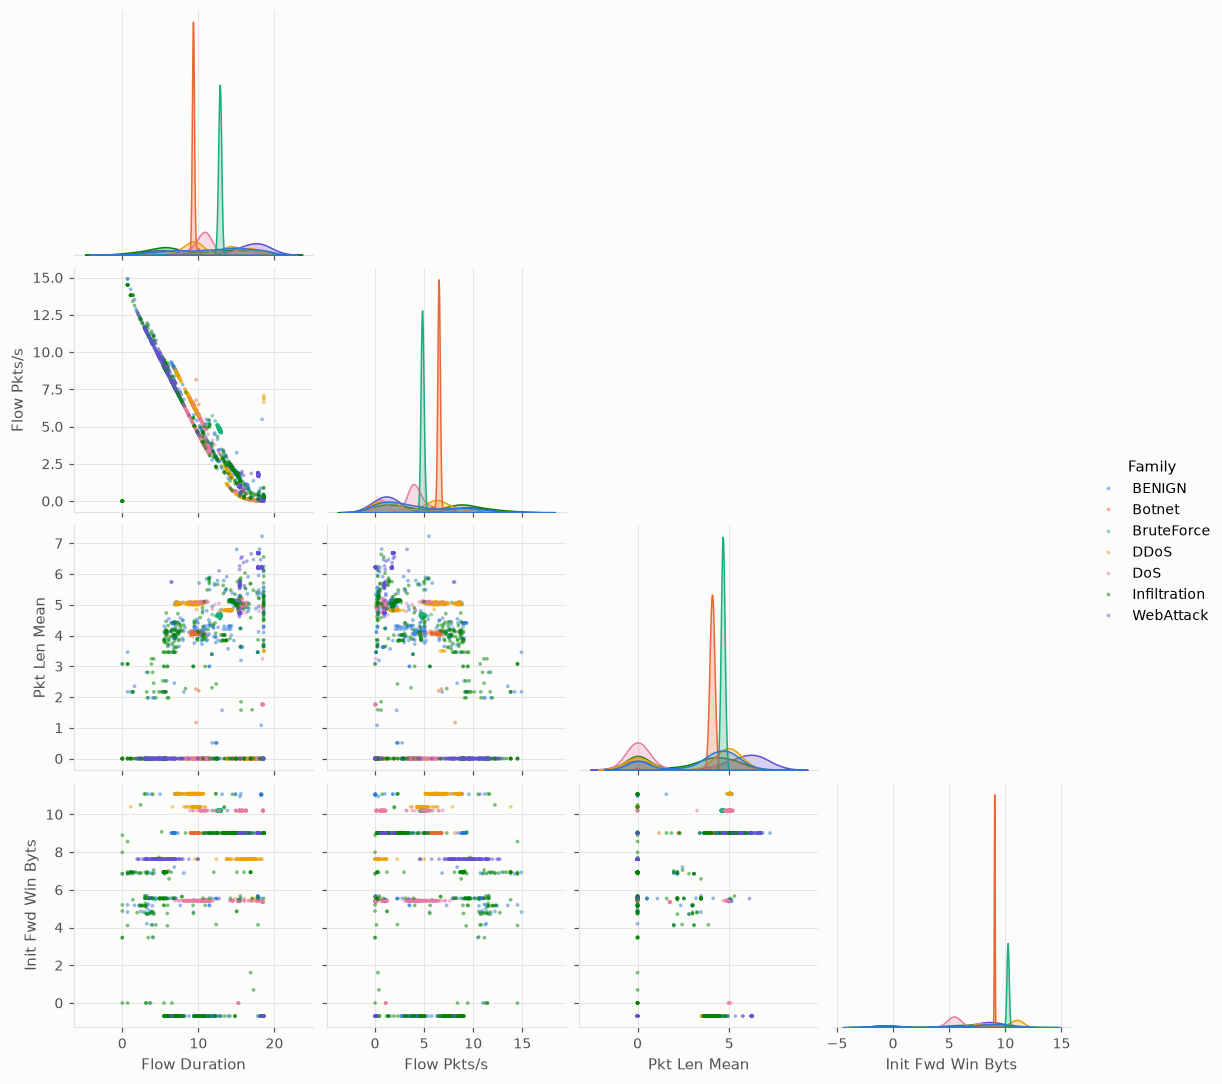

In [17]:
import seaborn as sns
pp = pd.concat([g.sample(min(len(g), 400), random_state=0) for _, g in sample.groupby('Family')])
pf = ['Flow Duration','Flow Pkts/s','Pkt Len Mean','Init Fwd Win Byts']
tmp = pp[pf].replace([np.inf,-np.inf], np.nan).fillna(0).apply(lambda s: np.sign(s)*np.log1p(np.abs(s)))
tmp['Family'] = pp['Family'].values
order = ['BENIGN'] + sorted(f for f in tmp.Family.unique() if f!='BENIGN')
g = sns.pairplot(tmp, hue='Family', hue_order=order, palette=viz.CATEGORICAL[:len(order)], plot_kws={'s':6,'alpha':0.5,'linewidth':0}, corner=True)
g.savefig(FIG/'eda_pairplot.png', dpi=110); plt.close('all')
Image(FIG/'eda_pairplot.png')

,mutual_info,rf_importance,lgbm_gain,xgb_gain,mean_rank
Dst Port,0.8818,0.09289,0.2531,0.04024,3
Fwd Header Len,0.8782,0.05378,0.06538,0.06821,4.75
Fwd Pkt Len Max,0.8755,0.02097,0.05154,0.03089,10.25
Init Fwd Win Byts,0.83,0.05442,0.05621,0.008118,11.5
Bwd Header Len,0.6967,0.02183,0.04839,0.09108,12
Fwd Seg Size Min,0.4722,0.07894,0.1361,0.2235,12.75
Fwd Pkt Len Mean,0.8778,0.01684,0.01367,0.01444,13.5
Fwd Act Data Pkts,0.4058,0.02509,0.1106,0.2149,14.5
Pkt Len Mean,0.861,0.02043,0.01083,0.009656,14.75
Fwd IAT Tot,0.8169,0.02148,0.01608,0.005284,15.25


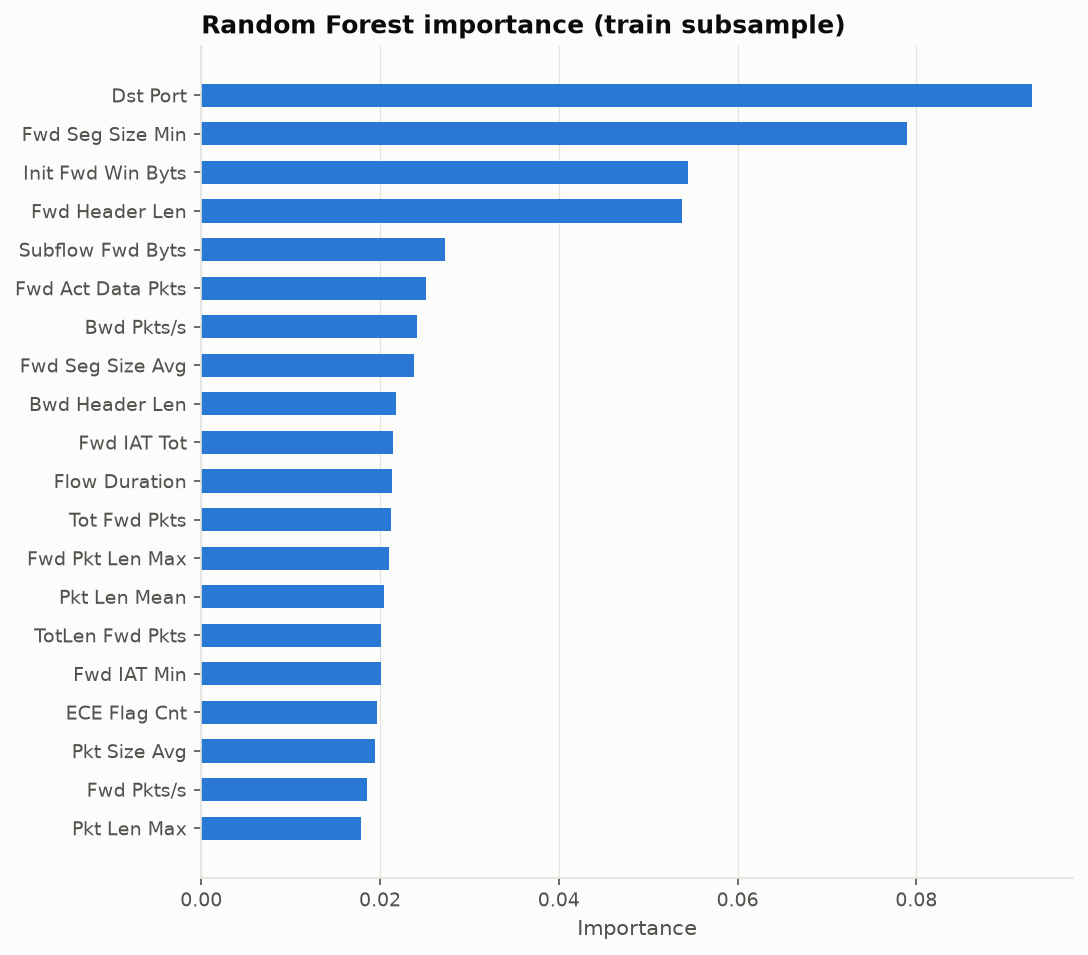

In [18]:
rank = pd.read_csv(METRICS/'feature_ranking.csv', index_col=0)
display(rank.head(20).style.format('{:.4g}'))
Image(FIG/'fs_rf_importance.png')

**Nhận xét.** Pairplot cho thấy các nhóm tấn công tạo thành cụm chặt (đặc biệt Botnet, BruteForce) còn BENIGN và Infiltration chồng lấn trên diện rộng. Bảng xếp hạng tổng hợp (mutual information, RF importance, LightGBM gain, XGBoost gain) đưa `Dst Port`, `Fwd Header Len`, `Fwd Pkt Len Max`, `Init Fwd Win Byts`, `Bwd Header Len` lên đầu: cổng dịch vụ, khối lượng dữ liệu chiều đi và kích thước gói lớn nhất. **Kết luận:** các đặc trưng quan trọng có ý nghĩa an ninh mạng rõ ràng (dịch vụ bị nhắm, lượng dữ liệu gửi, kích thước gói), nhưng hai trong năm đặc trưng đầu (`Dst Port`, `Init Fwd Win Byts`) có thể phụ thuộc testbed – được kiểm tra bằng ablation.

## Kết luận EDA

1. Dữ liệu có vấn đề chất lượng đáng kể: 26% dòng trùng lặp, hai lớp (FTP-BruteForce, SlowHTTPTest) gần như chỉ là một vài flow lặp lại, 22,359 vector mang nhiều nhãn, các file bị cắt ở giới hạn Excel, Inf/NaN ở cột tốc độ, cột hằng và cột trùng lặp do lỗi xuất CSV.
2. Mất cân bằng cực lớn (≈ 14,500 : 1) → đánh giá bằng macro-F1, recall từng lớp, FPR, PR-AUC.
3. Tấn công do công cụ sinh ra có phân phối rất tập trung → dễ phân loại; Infiltration chồng lấn với BENIGN → khó, cần báo cáo riêng.
4. Các đặc trưng như `Dst Port`, `Init Fwd Win Byts` vừa mạnh vừa có nguy cơ phản ánh testbed → giữ nhưng đo bằng ablation; các cột định danh/thời gian bị loại để tránh leakage.
5. Ngoại lai là đặc trưng của cả traffic bình thường lẫn tấn công → không loại.